# Exploring the recorded results

This notebook reads only the CSV files in `../results/` and `../docs/results.md`. It needs pandas and matplotlib and
no detector outputs or datasets. Terms follow [`../docs/glossary.md`](../docs/glossary.md); the idea of the test is
explained in [`../docs/concept.md`](../docs/concept.md).

One **cell** is one threshold τ selected in the **condition of selection** (files: `established` or `source`) so that
the false acceptance proportion (FAP) stays at or below the **limit α**, then tested on the **test part** of the
**condition of use** (files: `applied` or `target`). The Hoeffding-Bentkus interval [L, U] gives the outcome:
**applicable** (A) if U ≤ α, **not applicable** (N) if L > α, **not determined** (?) otherwise, and **no threshold
selected** (-) if the lowest candidate threshold fails in the condition of selection. Target limits are 10⁻², 10⁻³ and
10⁻⁴; the exploratory limits 0.05† and 0.1† define no performance target.

In [1]:
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RES = Path("../results")
DOCS = Path("../docs")
pd.set_option("display.width", 160)

CODE = {"applies": "A", "applicable": "A", "does not apply": "N", "not applicable": "N",
        "not determined": "?", "no threshold established": "-", "no threshold selected": "-"}
DATASET = {"kitti": "KITTI", "nuscenes": "nuScenes"}
ALPHAS = [0.01, 0.001, 0.0001, 0.05, 0.1]
LABEL = {0.01: "10⁻²", 0.001: "10⁻³", 0.0001: "10⁻⁴", 0.05: "0.05†", 0.1: "0.1†"}
ROWS = [("KITTI distance", "near", "far"), ("KITTI distance", "far", "near"),
        ("nuScenes distance", "near", "far"), ("nuScenes distance", "far", "near"),
        ("nuScenes weather", "clear", "rain"), ("nuScenes weather", "rain", "clear"),
        ("change of dataset and detector", "nuScenes", "KITTI"), ("change of dataset and detector", "KITTI", "nuScenes")]


def unify(df, pair, sel="established", use="applied", split="seed"):
    """One table layout for all run files: pair, selection, use, indicator, alpha, split, code."""
    out = pd.DataFrame({"pair": pair if isinstance(pair, str) else pair.values,
                        "selection": df[sel].replace(DATASET).values, "use": df[use].replace(DATASET).values,
                        "indicator": df["indicator"].values, "alpha": df["alpha"].values,
                        "split": df[split].values, "code": df["outcome"].map(CODE).values})
    assert out.code.notna().all()
    return out


def counts(codes):
    """Outcome counts over the splits in the order A, ?, N, - (as in docs/results.md), e.g. 'A1 ?3 N1'."""
    n = codes.value_counts()
    return " ".join(f"{c}{n[c]}" for c in "A?N-" if c in n)


def table(cells, alphas=ALPHAS):
    """Rows: pair and transfer; columns: indicator and limit; entries: outcome counts over splits 0 to 4."""
    t = cells[cells.selection != cells.use]
    assert (t.groupby(["pair", "selection", "use", "indicator", "alpha"]).size() == 5).all()
    g = t[t.alpha.isin(alphas)].groupby(["pair", "selection", "use", "indicator", "alpha"]).code.apply(counts)
    g = g.unstack(["indicator", "alpha"])
    g = g.reindex(index=pd.MultiIndex.from_tuples(ROWS),
                  columns=pd.MultiIndex.from_product([["u_s", "u_e"], alphas]))
    g.columns = [f"{i} {LABEL[a]}" for i, a in g.columns]
    g.index = [f"{p}: {s} → {u}" for p, s, u in g.index]
    return g

## (a) Main outcome table, frame-level evaluation

Sources, as named in `docs/results.md`: KITTI distance from
`m6_protocol_seeds_weather/A_kitti_range_protocol.csv` with the KITTI rule (`protocol` = `kitti_ignore`); nuScenes
distance and nuScenes weather from `m7_scene_split/m7_scene_split.csv`, `variant` = `frame` (these rows reproduce m3 and
m6 C, see `m7_scene_split/REPRO_PASSED.txt`); change of dataset and detector from
`m6_protocol_seeds_weather/B_shift_seeds_protocol.csv` with the KITTI rule. In the frame-level evaluation the frames are
divided into the parts at random and each frame is one unit of the test (Fig. 4 of the paper).

The table is rebuilt from the files and compared with the table "Outcomes over the five splits" of
`docs/results.md`. The `assert` stops the notebook if a single entry differs.

In [2]:
m6a = pd.read_csv(RES / "m6_protocol_seeds_weather/A_kitti_range_protocol.csv")
m6b = pd.read_csv(RES / "m6_protocol_seeds_weather/B_shift_seeds_protocol.csv")
m7 = pd.read_csv(RES / "m7_scene_split/m7_scene_split.csv")
m8a = pd.read_csv(RES / "m8_kitti_drive_split/A_kitti_distance_drive.csv")
m8b = pd.read_csv(RES / "m8_kitti_drive_split/B_dataset_drive.csv")
SETTING = {"distance": "nuScenes distance", "rain": "nuScenes weather"}


def m7_cells(variant):
    d = m7[m7.variant == variant]
    return unify(d, d.setting.map(SETTING))


rule = lambda d: d[d.protocol == "kitti_ignore"]
frame = pd.concat([unify(rule(m6a), "KITTI distance"), m7_cells("frame"),
                   unify(rule(m6b), "change of dataset and detector", "source", "target")])
main = table(frame, [0.01, 0.05, 0.1])
main

,u_s 10⁻²,u_s 0.05†,u_s 0.1†,u_e 10⁻²,u_e 0.05†,u_e 0.1†
KITTI distance: near → far,A1 ?3 N1,N5,N5,A5,?3 N2,N5
KITTI distance: far → near,A4 ?1,A5,A5,?5,A5,A5
nuScenes distance: near → far,A5,A4 ?1,N5,A5,A5,N5
nuScenes distance: far → near,?5,A2 ?3,A5,?2 N3,?5,A5
nuScenes weather: clear → rain,?2 -3,?5,?4 N1,?5,?4 N1,?1 N4
nuScenes weather: rain → clear,-5,A5,A5,A5,A5,A5
change of dataset and detector: nuScenes → KITTI,N5,N5,N5,A5,A5,A5
change of dataset and detector: KITTI → nuScenes,A5,A5,A5,?5,?5,?5


In [3]:
# The table in docs/results.md, read as text
sec = (DOCS / "results.md").read_text(encoding="utf-8").split("## Outcomes over the five splits")[1].split("\n## ")[0]
lines = [l for l in sec.splitlines() if l.startswith("| ") and not l.startswith("| setting") and "---" not in l]
doc = {}
for l in lines:
    c = [x.strip() for x in l.strip("|").split("|")]
    pair = "change of dataset and detector" if c[0] == "change of dataset" else c[0]
    doc[f"{pair}: {c[1]}"] = [x.replace("–", "-") for x in c[2:]]
doc = pd.DataFrame.from_dict(doc, orient="index", columns=main.columns)

assert doc.index.tolist() == main.index.tolist()
assert (doc == main).all().all(), (doc != main)
# docs/results.md also states that no threshold was selected at 10⁻³ and 10⁻⁴ in any setting
assert (frame[frame.alpha.isin([0.001, 0.0001])].code == "-").all()
print(f"docs/results.md reproduced: {main.size} entries equal; 10⁻³ and 10⁻⁴: no threshold selected in all "
      f"{(frame.alpha.isin([0.001, 0.0001])).sum()} cells")

docs/results.md reproduced: 48 entries equal; 10⁻³ and 10⁻⁴: no threshold selected in all 320 cells


## (b) Third run, sequence-level evaluation and the post-hoc sequence test

Frames of one recorded sequence (a KITTI drive or a nuScenes scene) are not independent. In the division by recorded
sequence, whole sequences are divided into the parts (m7 for nuScenes scenes, m8 for KITTI drives; for the change of
dataset and detector the KITTI side is divided by drive and the nuScenes side by scene). Two evaluations use this
division; the code below prints them under their file labels:

* **third run** (printed as "variant (i)"): division by recorded sequence, the frame as unit of the test
  (m7 `variant` = `scene_frame_unit`, m8 `hb_unit` = `frame`);
* **sequence-level evaluation** (printed as "variant (ii)"): division by recorded sequence, the recorded sequence as
  unit; the value of a sequence is the mean of the per-frame share a_f over its frames in the condition
  (m7 `variant` = `scene_scene_unit`, m8 `hb_unit` = `drive`).

All KITTI rows use the KITTI rule. All five limits are shown.

In [4]:
def seq_cells(m7_variant, hb_unit):
    return pd.concat([unify(rule(m8a[m8a.hb_unit == hb_unit]), "KITTI distance"), m7_cells(m7_variant),
                      unify(rule(m8b[m8b.hb_unit == hb_unit]), "change of dataset and detector", "source", "target")])


seq_i = seq_cells("scene_frame_unit", "frame")
seq_ii = seq_cells("scene_scene_unit", "drive")
print("variant (i): division by recorded sequence, unit frame")
display(table(seq_i))
print("variant (ii): division by recorded sequence, unit recorded sequence")
display(table(seq_ii))

variant (i): division by recorded sequence, unit frame


,u_s 10⁻²,u_s 10⁻³,u_s 10⁻⁴,u_s 0.05†,u_s 0.1†,u_e 10⁻²,u_e 10⁻³,u_e 10⁻⁴,u_e 0.05†,u_e 0.1†
KITTI distance: near → far,A1 ?2 N1 -1,-5,-5,N5,N5,A2 ?2 -1,-5,-5,?2 N3,N5
KITTI distance: far → near,A3 ?1 -1,-5,-5,A4 -1,A5,?4 -1,-5,-5,A4 -1,A5
nuScenes distance: near → far,A5,-5,-5,A2 ?2 N1,?1 N4,A5,-5,-5,A3 ?1 N1,N5
nuScenes distance: far → near,A2 ?3,-5,-5,A3 ?2,A5,?4 N1,-5,-5,A1 ?4,A5
nuScenes weather: clear → rain,A1 ?3 -1,-5,-5,?4 N1,?3 N2,A2 ?3,-5,-5,?3 N2,?1 N4
nuScenes weather: rain → clear,-5,-5,-5,A5,A5,A3 ?1 -1,-5,-5,A5,A5
change of dataset and detector: nuScenes → KITTI,N5,-5,-5,N5,N5,A4 ?1,-5,-5,A5,A4 ?1
change of dataset and detector: KITTI → nuScenes,A5,-5,-5,A5,A5,A2 ?3,-5,-5,A2 ?1 N2,A2 ?2 N1


variant (ii): division by recorded sequence, unit recorded sequence


,u_s 10⁻²,u_s 10⁻³,u_s 10⁻⁴,u_s 0.05†,u_s 0.1†,u_e 10⁻²,u_e 10⁻³,u_e 10⁻⁴,u_e 0.05†,u_e 0.1†
KITTI distance: near → far,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
KITTI distance: far → near,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
nuScenes distance: near → far,-5,-5,-5,?1 -4,A2 ?3,-5,-5,-5,?4 -1,A2 ?3
nuScenes distance: far → near,-5,-5,-5,-5,A1 ?4,-5,-5,-5,?5,?5
nuScenes weather: clear → rain,-5,-5,-5,-5,?5,-5,-5,-5,-5,?5
nuScenes weather: rain → clear,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
change of dataset and detector: nuScenes → KITTI,-5,-5,-5,?5,?5,-5,-5,-5,?5,?5
change of dataset and detector: KITTI → nuScenes,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5


**Post-hoc sequence test (Method A)** (`results/post_hoc/outcomes.csv`, `method` = `A`) was added after the parameters
of the study were fixed and the outcomes were known, and is not reported in the paper. `results/post_hoc/REPORT.md`
calls it "sequence-level test"; it is not the sequence-level evaluation of the paper. It keeps the recorded sequence
as the independent unit and the per-frame target: each sequence enters the test through a transformed value Y in
[0, 1] whose mean is at most α exactly when the FAP is at most α (see `results/post_hoc/README.md`). It uses the
division by recorded sequence above.

In [5]:
post = pd.read_csv(RES / "post_hoc/outcomes.csv")
post_a = post[post.method == "A"]
assert (post_a.own_condition == (post_a.established == post_a.applied)).all()
post_a_cells = unify(post_a, post_a.pair, split="split")
print("post-hoc Method A: division by recorded sequence, unit recorded sequence")
table(post_a_cells)

post-hoc Method A: division by recorded sequence, unit recorded sequence


,u_s 10⁻²,u_s 10⁻³,u_s 10⁻⁴,u_s 0.05†,u_s 0.1†,u_e 10⁻²,u_e 10⁻³,u_e 10⁻⁴,u_e 0.05†,u_e 0.1†
KITTI distance: near → far,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
KITTI distance: far → near,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
nuScenes distance: near → far,-5,-5,-5,-5,A2 -3,-5,-5,-5,-5,A3 ?1 -1
nuScenes distance: far → near,-5,-5,-5,-5,?5,-5,-5,-5,-5,?5
nuScenes weather: clear → rain,-5,-5,-5,-5,?5,-5,-5,-5,-5,?5
nuScenes weather: rain → clear,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5
change of dataset and detector: nuScenes → KITTI,-5,-5,-5,-5,?5,-5,-5,-5,-5,?5
change of dataset and detector: KITTI → nuScenes,-5,-5,-5,-5,-5,-5,-5,-5,-5,-5


## (c) Retention of applicable transfers at 10⁻²

Retention R is the share of the correct detections of the condition of use that the threshold accepts. The file
`results/supporting_analyses/retention_applicable_cells.csv` lists every applicable cell; `in_fig_outcomes` = True
marks the transfers of the main outcome table in (a). The table gives, per transfer and indicator at the target limit
10⁻², the number of applicable splits and the median and maximum retention over them.

In [6]:
ret = pd.read_csv(RES / "supporting_analyses/retention_applicable_cells.csv")
r = ret[ret.in_fig_outcomes & (ret.alpha == 0.01)].copy()
assert r.transfer.all() and (r.outcome == "applies").all() and (r.variant == "frame").all()
# the file names two pairs of conditions by their older names
r["setting"] = r.setting.replace({"change of dataset": "change of dataset and detector",
                                  "nuScenes rain": "nuScenes weather"})
summary = (r.groupby(["setting", "established", "applied", "indicator"]).R_hat
             .agg(applicable_splits="size", median_retention="median", max_retention="max").reset_index())
summary

,setting,established,applied,indicator,applicable_splits,median_retention,max_retention
0,KITTI distance,far,near,u_s,4,0.079701,0.149845
1,KITTI distance,near,far,u_e,5,0.057012,0.111261
2,KITTI distance,near,far,u_s,1,0.018457,0.018457
3,change of dataset and detector,KITTI,nuScenes,u_s,5,0.000077,0.000229
4,change of dataset and detector,nuScenes,KITTI,u_e,5,0.236104,0.285080
5,nuScenes distance,near,far,u_e,5,0.003760,0.010726
6,nuScenes distance,near,far,u_s,5,0.004595,0.005933
7,nuScenes weather,rain,clear,u_e,5,0.025663,0.057814


In [7]:
# The applicable-split counts agree with the A counts of the main table at 10⁻²
for _, s in summary.iterrows():
    key = f"{s.setting}: {s.established} → {s.applied}"
    entry = main.loc[key, f"{s.indicator} 10⁻²"]
    assert f"A{s.applicable_splits}" in entry.split(), (key, entry)
print("applicable splits agree with table (a)")

applicable splits agree with table (a)


## (d) Minimum number of independent units

To show A ≤ α at error probability δ′ the test needs at least n ≥ ln δ′ / ln(1 − α) independent units without any
false acceptance (the zero-failure bound, Eq. 5 of the paper). With δ = 0.05, δ′ = δ = 0.05 applies to the selection
and δ′ = δ/2 = 0.025 to the test. This is a lower bound: false acceptances in the data raise the number needed.

In [8]:
nmin = pd.DataFrame([{"limit α": LABEL[a], "n (δ′ = 0.05)": math.ceil(math.log(0.05) / math.log(1 - a)),
                      "n (δ′ = 0.025)": math.ceil(math.log(0.025) / math.log(1 - a))} for a in ALPHAS])
nmin

,limit α,n (δ′ = 0.05),n (δ′ = 0.025)
0,10⁻²,299,368
1,10⁻³,2995,3688
2,10⁻⁴,29956,36887
3,0.05†,59,72
4,0.1†,29,36


Units available in split 0: frames per condition in the selection part and the test part
(`supporting_analyses/frames_per_condition.csv`, division by frame) and recorded sequences per condition over all
parts (`post_hoc/ns_per_condition.csv`). A ✓ marks a limit for which the test part holds at least the minimum number
of units at δ′ = 0.025 (frames), or for which the sequences of the whole condition reach it (sequences; the test part
holds fewer).

In [9]:
fr = pd.read_csv(RES / "supporting_analyses/frames_per_condition.csv").query("seed == 0").copy()
fr["setting"] = fr.setting.replace({"change of dataset": "change of dataset and detector",
                                    "nuScenes rain": "nuScenes weather"})
ns = pd.read_csv(RES / "post_hoc/ns_per_condition.csv").query("split == 0")
need = {LABEL[a]: math.ceil(math.log(0.025) / math.log(1 - a)) for a in ALPHAS}
fr_t = fr[["setting", "condition", "frames_select", "frames_eval"]].copy()
for lab, n in need.items():
    fr_t[lab] = fr_t.frames_eval.map(lambda x: "✓" if x >= n else "")
ns_t = ns[["pair", "condition", "sequences", "frames"]].copy()
for lab, n in need.items():
    ns_t[lab] = ns_t.sequences.map(lambda x: "✓" if x >= n else "")
print("frames, division by frame, split 0")
display(fr_t)
print("recorded sequences per condition, split 0 (all parts)")
display(ns_t)

frames, division by frame, split 0


,setting,condition,frames_select,frames_eval,10⁻²,10⁻³,10⁻⁴,0.05†,0.1†
0,KITTI distance (KITTI rule),near,1484,1500,✓,,,✓,✓
1,KITTI distance (KITTI rule),far,1514,1545,✓,,,✓,✓
2,nuScenes distance,near,2207,2209,✓,,,✓,✓
3,nuScenes distance,far,2270,2276,✓,,,✓,✓
4,nuScenes weather,clear,1917,1900,✓,,,✓,✓
5,nuScenes weather,rain,392,414,✓,,,✓,✓
6,change of dataset and detector,KITTI (KITTI rule),1844,1852,✓,,,✓,✓
7,change of dataset and detector,nuScenes,2849,2850,✓,,,✓,✓


recorded sequences per condition, split 0 (all parts)


,pair,condition,sequences,frames,10⁻²,10⁻³,10⁻⁴,0.05†,0.1†
0,KITTI distance,near,44,3322,,,,,✓
1,KITTI distance,far,26,3382,,,,,
10,nuScenes distance,near,149,4754,,,,✓,✓
11,nuScenes distance,far,150,5172,,,,✓,✓
20,nuScenes weather,clear,111,4235,,,,✓,✓
21,nuScenes weather,rain,24,910,,,,,
30,change of dataset and detector,KITTI,45,3696,,,,,✓
31,change of dataset and detector,nuScenes,150,5699,,,,✓,✓


## (e) AUROC intervals (post hoc)

`results/post_hoc/auroc_bootstrap.csv` gives 95 % percentile bootstrap intervals of the AUROC (wrong detections as the
positive class) for the three pairs of conditions of the separation figure (Fig. 5), test part of split 0, with
recorded sequences resampled, and for the differences between the two conditions of a pair. The intervals were added
post hoc; the paper reports the AUROC values (column `point`) as point estimates.

In [10]:
au = pd.read_csv(RES / "post_hoc/auroc_bootstrap.csv")
au[["pair", "indicator", "quantity", "point", "lo95", "hi95", "detections", "sequences", "replicates"]]

,pair,indicator,quantity,point,lo95,hi95,detections,sequences,replicates
0,KITTI distance,u_s,AUROC near,0.914795,0.884452,0.946326,6310,39.0,2000
1,KITTI distance,u_s,AUROC far,0.845460,0.830982,0.859992,5957,25.0,2000
2,KITTI distance,u_s,AUROC far - AUROC near,-0.069334,-0.091117,-0.046404,12267,NaN,2000
3,nuScenes weather,u_e,AUROC clear,0.844086,0.819268,0.868640,13857,111.0,2000
4,nuScenes weather,u_e,AUROC rain,0.856342,0.821496,0.886535,3122,24.0,2000
5,nuScenes weather,u_e,AUROC rain - AUROC clear,0.012256,-0.030045,0.051010,16979,NaN,2000
6,change of dataset and detector,u_s,AUROC nuScenes,0.748730,0.733961,0.764666,19999,150.0,2000
7,change of dataset and detector,u_s,AUROC KITTI,0.905310,0.886003,0.922009,13707,42.0,2000
8,change of dataset and detector,u_s,AUROC KITTI - AUROC nuScenes,0.156580,0.132660,0.179923,33706,NaN,2000


## (f) Outcome grid

The main table of (a) drawn as a grid: one row per transfer, one column per indicator and limit, five squares per
cell for splits 0 to 4. Colours (Okabe-Ito) and letters both encode the outcome; grey columns are the exploratory
limits 0.05† and 0.1†.

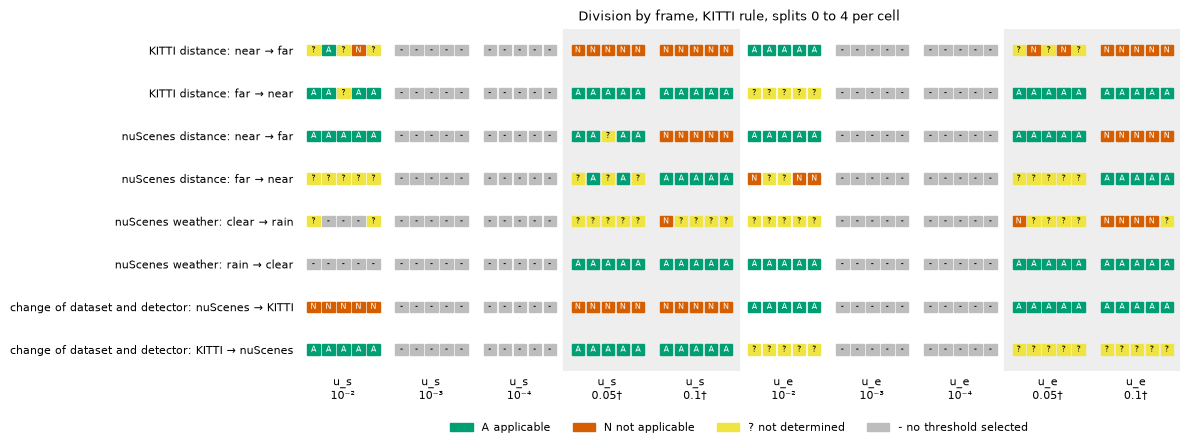

In [11]:
COL = {"A": "#009e73", "N": "#d55e00", "?": "#f0e442", "-": "#bdbdbd"}
TXT = {"A": "white", "N": "white", "?": "black", "-": "black"}
cols = [(i, a) for i in ["u_s", "u_e"] for a in ALPHAS]
fig, ax = plt.subplots(figsize=(12, 4.6))
for y, (p, s, u) in enumerate(ROWS):
    for x, (ind, a) in enumerate(cols):
        if a >= 0.05:
            ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, color="#eeeeee", zorder=0))
        c = frame[(frame.pair == p) & (frame.selection == s) & (frame.use == u) & (frame.indicator == ind)
                  & (frame.alpha == a)].sort_values("split")
        for k, code_ in enumerate(c.code):
            xx = x - 0.4 + k * 0.17
            ax.add_patch(plt.Rectangle((xx, y - 0.12), 0.14, 0.24, color=COL[code_]))
            ax.text(xx + 0.07, y, code_, ha="center", va="center", fontsize=6, color=TXT[code_])
ax.set_xlim(-0.5, len(cols) - 0.5)
ax.set_ylim(len(ROWS) - 0.5, -0.5)
ax.set_xticks(range(len(cols)), [f"{i}\n{LABEL[a]}" for i, a in cols], fontsize=8)
ax.set_yticks(range(len(ROWS)), [f"{p}: {s} → {u}" for p, s, u in ROWS], fontsize=8)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[k]) for k in COL]
ax.legend(handles, ["A applicable", "N not applicable", "? not determined", "- no threshold selected"],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
ax.set_title("Division by frame, KITTI rule, splits 0 to 4 per cell", fontsize=9)
fig.tight_layout()
plt.show()